# 01 — Análise Exploratória (EDA)

**Objetivo:** conhecer o dataset UCI *Default of Credit Card Clients* e transformar o que
ele mostra em **decisões registradas**: limpeza da referência, domínios do contrato de dados
(Etapa 1), variáveis candidatas ao drift (Etapa 2) e pontos de atenção de viés (Etapa 4).

| Item | Valor |
|------|-------|
| Fonte | UCI ML Repository, id 350 — licença CC BY 4.0 |
| Atribuição | Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H |
| Pré-requisito | `uv run python scripts/download_data.py` |

> 🔐 **Prática de governança:** este notebook mostra apenas **agregados** (contagens, taxas,
> quantis). Nenhuma linha individual de cliente é exibida, embora a licença permitisse — é a
> mesma regra aplicada aos relatórios versionados em `reports/`.

> ℹ️ O notebook usa as **mesmas funções de `src/`** que o pipeline (`load_raw`,
> `clean_reference`). Ele é o registro da análise, não um passo de build.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import get_seed, load_config
from src.data.cleaning import clean_reference
from src.data.loader import DataSource, load_raw
from src.data.schema import BILL_COLUMNS, PAY_AMOUNT_COLUMNS, PAY_STATUS_COLUMNS, TARGET_COLUMN

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (9, 3.5)
SEED = get_seed()
df = load_raw(DataSource.REAL)

## 1. Perfil geral

In [2]:
profile = pd.Series(
    {
        "linhas": len(df),
        "colunas": df.shape[1],
        "nulos": int(df.isna().sum().sum()),
        "IDs únicos": df["ID"].is_unique,
        "inadimplência": round(df[TARGET_COLUMN].mean(), 4),
    }
)
profile

linhas           30000
colunas             25
nulos                0
IDs únicos        True
inadimplência   0.2212
dtype: object

In [3]:
df.drop(columns="ID").describe().T[["min", "25%", "50%", "75%", "max"]]

,min,25%,50%,75%,max
LIMIT_BAL,10000.0000,50000.0000,140000.0000,240000.0000,1000000.0000
SEX,1.0000,1.0000,2.0000,2.0000,2.0000
EDUCATION,0.0000,1.0000,2.0000,2.0000,6.0000
MARRIAGE,0.0000,1.0000,2.0000,2.0000,3.0000
AGE,21.0000,28.0000,34.0000,41.0000,79.0000
PAY_0,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_2,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_3,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_4,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_5,-2.0000,-1.0000,0.0000,0.0000,8.0000


**Leitura:** 30.000 clientes, **nenhum nulo**, inadimplência de **22,12%**. O
desbalanceamento é moderado: um classificador que diz "ninguém fica inadimplente" acerta
~78%, por isso acurácia **não** é métrica deste projeto (AUC-ROC, KS e recall).

## 2. Domínios × dicionário da UCI

In [4]:
dictionary = {
    "EDUCATION": {1, 2, 3, 4},
    "MARRIAGE": {1, 2, 3},
    "SEX": {1, 2},
}
rows = []
for column, valid in dictionary.items():
    counts = df[column].value_counts().sort_index()
    for value, n in counts.items():
        rows.append(
            {
                "coluna": column,
                "código": value,
                "linhas": n,
                "no dicionário": value in valid,
                "inadimplência": df.loc[df[column] == value, TARGET_COLUMN].mean(),
            }
        )
pd.DataFrame(rows)

,coluna,código,linhas,no dicionário,inadimplência
0,EDUCATION,0,14,False,0.0000
1,EDUCATION,1,10585,True,0.1923
2,EDUCATION,2,14030,True,0.2373
3,EDUCATION,3,4917,True,0.2516
4,EDUCATION,4,123,True,0.0569
5,EDUCATION,5,280,False,0.0643
6,EDUCATION,6,51,False,0.1569
7,MARRIAGE,0,54,False,0.0926
8,MARRIAGE,1,13659,True,0.2347
9,MARRIAGE,2,15964,True,0.2093


**Decisões (registradas em `configs/pipeline.yaml`, seção `cleaning`):**

- `EDUCATION` 0, 5 e 6 (345 linhas) **não existem no dicionário**. A inadimplência deles
  (0% · 6,4% · 15,7%) é próxima do código 4 "outros" (5,7%) e distante dos demais (19–25%).
  → **Na referência:** agrupar em 4. **Em produção:** o contrato rejeita (regra C6).
- `MARRIAGE` 0 (54 linhas) também não existe. → Agrupar em 3 "outros" na referência;
  rejeitar em produção.
- `SEX` está inteiramente dentro do dicionário.

In [5]:
pay = df[PAY_STATUS_COLUMNS]
pd.DataFrame(
    {
        "mín": pay.min(),
        "máx": pay.max(),
        "% = -2": (pay == -2).mean() * 100,
        "% = 0": (pay == 0).mean() * 100,
    }
)

,mín,máx,% = -2,% = 0
PAY_0,-2,8,9.1967,49.1233
PAY_2,-2,8,12.6067,52.4333
PAY_3,-2,8,13.6167,52.5467
PAY_4,-2,8,14.4933,54.8500
PAY_5,-2,8,15.1533,56.4900
PAY_6,-2,8,16.3167,54.2867


`PAY_*` vai de **−2 a 8**. O dicionário só documenta −1 (pago em dia) e 1–9 (meses de
atraso); −2 e 0 são frequentes e **não documentados** (interpretação usual: sem consumo e
crédito rotativo). → Contrato aceita o domínio **[−2, 9]** (regra C7).

## 3. Linhas duplicadas

In [6]:
features = [c for c in df.columns if c != "ID"]
in_pairs = df.duplicated(subset=features, keep=False)
inactive = (df[BILL_COLUMNS + PAY_AMOUNT_COLUMNS] == 0).all(axis=1)
pd.Series(
    {
        "linhas em pares idênticos": int(in_pairs.sum()),
        "cópias extras": int(df.duplicated(subset=features).sum()),
        "  ...das quais sem nenhuma movimentação": int((in_pairs & inactive).sum()),
        "  ...com movimentação idêntica": int((in_pairs & ~inactive).sum()),
    }
)

linhas em pares idênticos                  70
cópias extras                              35
  ...das quais sem nenhuma movimentação    60
  ...com movimentação idêntica             10
dtype: int64

In [7]:
x_cols = [c for c in features if c != TARGET_COLUMN]
same_x = df.duplicated(subset=x_cols, keep=False)
conflicts = df[same_x].groupby(x_cols)[TARGET_COLUMN].nunique().gt(1).sum()
pd.Series(
    {
        "linhas com features idênticas (qualquer rótulo)": int(same_x.sum()),
        "grupos com rótulos opostos": int(conflicts),
    }
)

linhas com features idênticas (qualquer rótulo)    108
grupos com rótulos opostos                          21
dtype: int64

**Leitura:**

- São **35 pares** de linhas idênticas em todas as 23 features **e** no target, com IDs
  diferentes. 60 das 70 linhas são clientes **sem nenhuma fatura ou pagamento** em seis
  meses: perfis coincidentes são plausíveis. As outras 10 têm movimentação idêntica, o que é
  suspeito de cadastro duplicado.
- Não há como distinguir os dois casos. **Decisão:** remover a cópia extra na referência
  (35 linhas, 0,12%). Custo desprezível, e elimina o risco de a mesma informação cair em
  treino e teste.
- Em produção, duplicata pelo `ID` bloqueia o lote (C3); perfil idêntico com ID diferente
  vira **aviso** (W4).
- Existem **21 grupos** de clientes com features idênticas e **rótulos opostos**: ruído de
  rótulo que nenhum modelo resolve. É um limite inferior para o erro — registrado no Model
  Card.

## 4. Relação das variáveis com a inadimplência

,size,mean
PAY_0,,
-2,2759,0.1323
-1,5686,0.1678
0,14737,0.1281
1,3688,0.3395
2,2667,0.6914
3,322,0.7578
4,76,0.6842
5,26,0.5000
6,11,0.5455


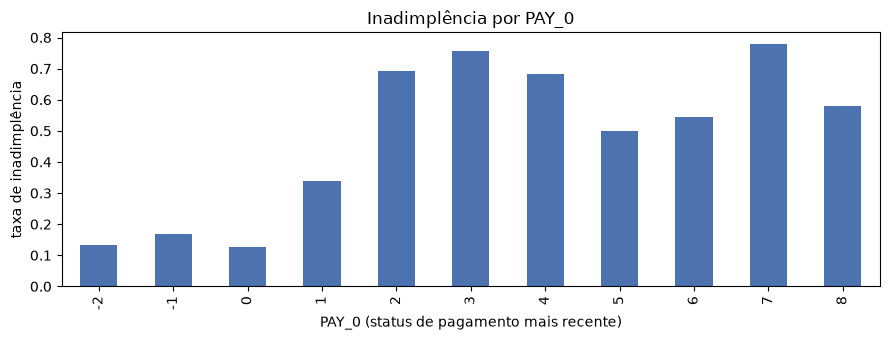

In [8]:
rate_by_pay0 = df.groupby("PAY_0")[TARGET_COLUMN].agg(["size", "mean"])
ax = rate_by_pay0["mean"].plot.bar(color="#4C72B0", title="Inadimplência por PAY_0")
ax.set_ylabel("taxa de inadimplência")
ax.set_xlabel("PAY_0 (status de pagamento mais recente)")
plt.tight_layout()
rate_by_pay0

`PAY_0` é de longe o sinal mais forte: a inadimplência salta de ~13–17% (em dia) para
**34%** com 1 mês de atraso e **69%** com 2 meses. Implicação para a Etapa 2: um drift em
`PAY_0` (aperto econômico, mais atrasos) atinge diretamente a variável que mais pesa.

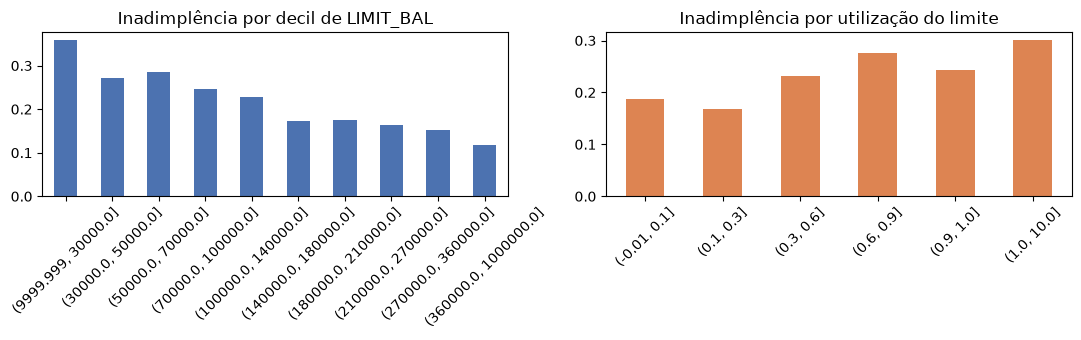

In [9]:
limit_bins = pd.qcut(df["LIMIT_BAL"], 10, duplicates="drop")
utilization = df["BILL_AMT1"].clip(lower=0) / df["LIMIT_BAL"]
util_bins = pd.cut(utilization, [-0.01, 0.1, 0.3, 0.6, 0.9, 1.0, 10])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby(limit_bins, observed=True)[TARGET_COLUMN].mean().plot.bar(
    ax=axes[0], color="#4C72B0", title="Inadimplência por decil de LIMIT_BAL"
)
df.groupby(util_bins, observed=True)[TARGET_COLUMN].mean().plot.bar(
    ax=axes[1], color="#DD8452", title="Inadimplência por utilização do limite"
)
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

- **Limite maior → menos inadimplência**: o banco já concede mais a quem considera melhor
  pagador. `LIMIT_BAL` é, em parte, uma decisão de crédito anterior embutida nos dados.
- **Utilização do limite** (`BILL_AMT1 / LIMIT_BAL`) cresce junto com a inadimplência. É a
  variável natural para o **concept drift** da Etapa 2 (inadimplência sobe para alta
  utilização) e para o **drift nominal** (inflação aumenta faturas).

In [10]:
bill_corr = df[BILL_COLUMNS].corr()
bill_corr.round(3)

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.0000,0.9510,0.8920,0.8600,0.8300,0.8030
BILL_AMT2,0.9510,1.0000,0.9280,0.8920,0.8600,0.8320
BILL_AMT3,0.8920,0.9280,1.0000,0.9240,0.8840,0.8530
BILL_AMT4,0.8600,0.8920,0.9240,1.0000,0.9400,0.9010
BILL_AMT5,0.8300,0.8600,0.8840,0.9400,1.0000,0.9460
BILL_AMT6,0.8030,0.8320,0.8530,0.9010,0.9460,1.0000


`BILL_AMT1…6` são **muito correlacionadas** (0,95 entre meses vizinhos). Um drift
simulado em uma delas aparece em todas: o relatório de drift deve ser lido por grupo, e a
análise causal precisa considerar essa redundância antes de atribuir causa a uma coluna.

## 5. Atributos sensíveis (insumo para a auditoria de viés)

In [11]:
age_bins = pd.cut(df["AGE"], [20, 25, 30, 40, 50, 60, 80])
sensitive = {
    "SEX": df["SEX"],
    "faixa de AGE": age_bins,
    "EDUCATION": df["EDUCATION"],
    "MARRIAGE": df["MARRIAGE"],
}
tables = []
for name, groups in sensitive.items():
    table = df.groupby(groups, observed=True)[TARGET_COLUMN].agg(["size", "mean"])
    table.index = [f"{name} = {value}" for value in table.index]
    tables.append(table)
pd.concat(tables).rename(columns={"size": "clientes", "mean": "inadimplência"})

,clientes,inadimplência
SEX = 1,11888,0.2417
SEX = 2,18112,0.2078
"faixa de AGE = (20, 25]",3871,0.2666
"faixa de AGE = (25, 30]",7142,0.2015
"faixa de AGE = (30, 40]",10713,0.2043
"faixa de AGE = (40, 50]",6005,0.2330
"faixa de AGE = (50, 60]",1997,0.2524
"faixa de AGE = (60, 80]",272,0.2684
EDUCATION = 0,14,0.0000
EDUCATION = 1,10585,0.1923


**Leitura para a governança (Etapa 4):**

- **Sexo:** 24,2% (masculino) × 20,8% (feminino). Mesmo fora das features, o modelo pode
  reproduzir essa diferença por proxies — a auditoria mede o resultado por grupo.
- **Idade em U:** 26,7% até 25 anos e 26,8% acima de 60, contra ~20% entre 26 e 40. Usar
  `AGE` como feature pode penalizar os dois extremos; a decisão sai da ablação.
- **Escolaridade:** inadimplência cresce de pós-graduação (19%) para ensino médio (25%) —
  proxy socioeconômico.

Nenhum desses números é decisão ainda: eles definem **o que a auditoria precisa medir**
depois do modelo treinado.

## 6. Domínios propostos para o contrato de dados

In [12]:
contract_view = pd.DataFrame(
    {
        "mín observado": df[["AGE", "LIMIT_BAL", *PAY_AMOUNT_COLUMNS]].min(),
        "máx observado": df[["AGE", "LIMIT_BAL", *PAY_AMOUNT_COLUMNS]].max(),
        "p99,9": df[["AGE", "LIMIT_BAL", *PAY_AMOUNT_COLUMNS]].quantile(0.999),
    }
)
contract_view

,mín observado,máx observado,"p99,9"
AGE,21,79,69.0000
LIMIT_BAL,10000,1000000,700000.0000
PAY_AMT1,0,873552,231788.7690
PAY_AMT2,0,1684259,263113.1130
PAY_AMT3,0,896040,217035.9650
PAY_AMT4,0,621000,200396.6050
PAY_AMT5,0,426529,202319.6830
PAY_AMT6,0,528666,220076.2950


In [13]:
pd.Series(
    {
        "LIMIT_BAL múltiplo de 10.000": f"{(df['LIMIT_BAL'] % 10_000 == 0).mean():.4%}",
        "LIMIT_BAL > 800.000": int((df["LIMIT_BAL"] > 800_000).sum()),
        "clientes com alguma fatura negativa": int((df[BILL_COLUMNS] < 0).any(axis=1).sum()),
        "fatura > limite (BILL_AMT1)": f"{(df['BILL_AMT1'] > df['LIMIT_BAL']).mean():.2%}",
    }
)

LIMIT_BAL múltiplo de 10.000           99.9900%
LIMIT_BAL > 800.000                           1
clientes com alguma fatura negativa        1930
fatura > limite (BILL_AMT1)               7.05%
dtype: object

**Domínios propostos** (a formalizar em `docs/DATA_CONTRACTS.md`):

| Regra | Domínio | Base |
|-------|---------|------|
| C4 `AGE` | 18 a 100 | Exigência legal (≥ 18); observado 21–79 |
| C5 `LIMIT_BAL` | > 0 e ≤ 1.000.000 | Máximo observado é 1.000.000; só 1 cliente acima de 800 mil |
| C6 `EDUCATION` / `MARRIAGE` / `SEX` | dicionário | Seção 2 |
| C7 `PAY_*` | −2 a 9 | Seção 2 |
| C8 `PAY_AMT*` | ≥ 0 | Observado ≥ 0 |
| W1 `BILL_AMT*` | negativos permitidos | 1.930 clientes com crédito a favor |

> ⚠️ Fatura acima do limite existe (7% dos clientes em `BILL_AMT1`): **não** pode virar
> regra de bloqueio.

## 7. Efeito da limpeza (mesma função do pipeline)

In [14]:
cleaned, report = clean_reference(df, load_config()["cleaning"])
pd.Series(report.to_dict())

rows_in                       30000
education_recoded               345
marriage_recoded                 54
duplicate_profiles_dropped       35
rows_out                      29965
dtype: int64

## ✅ Decisões registradas

| # | Decisão | Onde vive |
|---|---------|-----------|
| 1 | `EDUCATION` 0/5/6 → 4 e `MARRIAGE` 0 → 3, **só na referência** | `configs/pipeline.yaml` → `cleaning` |
| 2 | Remover 35 cópias de perfis idênticos na referência | `configs/pipeline.yaml` → `cleaning` |
| 3 | Domínios do contrato (tabela da seção 6) | `docs/DATA_CONTRACTS.md` |
| 4 | Ruído de rótulo (21 grupos) declarado como limitação | `docs/MODEL_CARD.md` |
| 5 | `PAY_0`, utilização do limite e faturas são candidatas ao drift | `docs/DRIFT.md` |
| 6 | Auditoria de viés por sexo, faixa etária e escolaridade | README — Governança |

Próximo notebook: `02_baseline.ipynb` — split já feito por
`uv run python scripts/prepare_data.py`.